## 1.1 Importing data

In [1]:
import pandas as pd

df = pd.read_csv("../data/cities.csv")
print(df.head())
print(df.shape)

     City          X          Y
0  City_1  37.454012  95.071431
1  City_2  73.199394  59.865848
2  City_3  15.601864  15.599452
3  City_4   5.808361  86.617615
4  City_5  60.111501  70.807258
(50, 3)


## 1.2 Preparing coordinates

In [2]:
coords = list(zip(df["X"], df["Y"]))
print(len(coords))
print(coords[:3])

50
[(37.45401188, 95.07143064), (73.19939418, 59.86584842), (15.60186404, 15.59945203)]


## 1.3 Distance between cities

In [3]:
import math

In [4]:
def distance(a, b):
    x1, y1 = coords[a]
    x2, y2 = coords[b]
    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)

## Route length

In [5]:
def route_length(route):
    total = 0
    for i in range(len(route)):
        total += distance(route[i], route[(i + 1) % len(route)])
    return total

## Random route

In [6]:
import random

In [7]:
def random_route(n):
    route = list(range(n))
    random.shuffle(route)
    return route


random.seed(1)
r = random_route(50)
print(r[:10])
print(route_length(r))

[2, 15, 47, 9, 21, 29, 48, 5, 46, 14]
2723.3508829346997


## Plotting a route

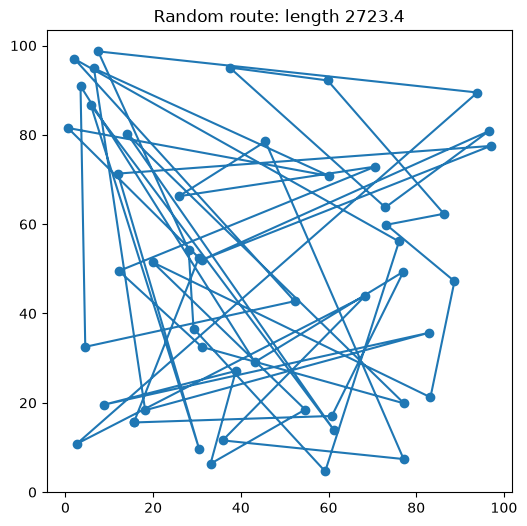

In [8]:
import matplotlib.pyplot as plt


def plot_route(route, title="Route"):
    order = route + [route[0]]
    xs = [coords[c][0] for c in order]
    ys = [coords[c][1] for c in order]
    plt.figure(figsize=(6, 6))
    plt.plot(xs, ys, "o-")
    plt.title(f"{title}: length {route_length(route):.1f}")
    plt.show()


plot_route(r, "Random route")

## Neighbour move

In [9]:
def swap_neighbour(route):
    new_route = route.copy()
    i, j = random.sample(range(len(route)), 2)
    new_route[i], new_route[j] = new_route[j], new_route[i]
    return new_route


r2 = swap_neighbour(r)
print(route_length(r), route_length(r2))

2723.3508829346997 2755.9881754159


## Hill climbing

In [10]:
def hill_climb(start, iterations):
    current = start
    current_len = route_length(current)
    history = [current_len]
    for _ in range(iterations):
        candidate = swap_neighbour(current)
        candidate_len = route_length(candidate)
        if candidate_len < current_len:
            current, current_len = candidate, candidate_len
        history.append(current_len)
    return current, history


random.seed(1)
start = random_route(50)
best, history = hill_climb(start, 10000)
print(history[0], history[-1])

2723.3508829346997 784.1518976844059


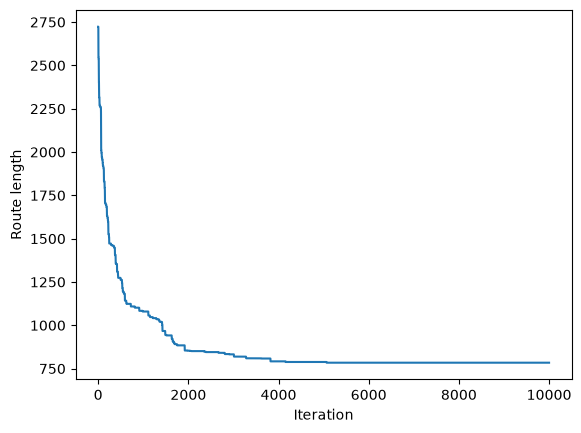

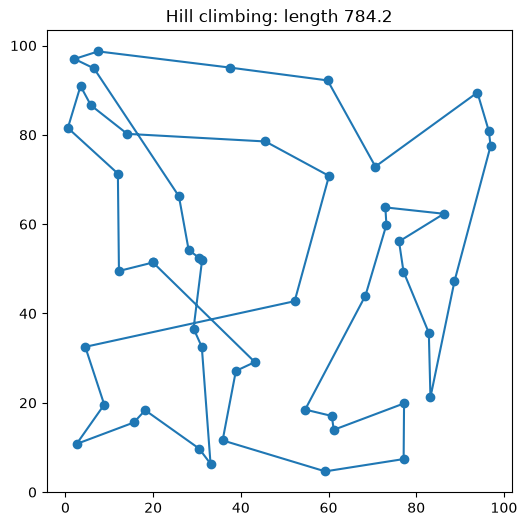

In [11]:
plt.plot(history)
plt.xlabel("Iteration")
plt.ylabel("Route length")
plt.show()

plot_route(best, "Hill climbing")

## Effect of the starting route

In [12]:
results = []
for seed in range(5):
    random.seed(seed)
    start = random_route(50)
    best, history = hill_climb(start, 10000)
    results.append(history[-1])

print(results)

[936.7955566788628, 784.1518976844059, 938.9637911588358, 859.3183122610633, 871.8481637347755]


In [13]:
def random_restart(n_cities, restarts, iterations):
    best_route, best_len = None, float("inf")
    for _ in range(restarts):
        route, history = hill_climb(random_route(n_cities), iterations)
        if history[-1] < best_len:
            best_route, best_len = route, history[-1]
    return best_route, best_len


random.seed(1)
best_rr, len_rr = random_restart(50, 5, 10000)
print(len_rr)

784.1518976844059
